---
title: "Angular Momentum and Spin — Level 2"
short_title: "06 Angular Momentum & Spin"
numbering:
  heading_2: true
  equation: true
---

# Angular Momentum and Spin

:::{seealso} Math for this topic
- [Q-M4: Rotations, angular momentum algebra and spherical harmonics](../math/04-rotations-spherical-harmonics.ipynb)
- [M6: Linear algebra](../../level2-book/math/06-linear-algebra.ipynb)
- [Q-M3: Hilbert space and Dirac notation](../math/03-hilbert-space-dirac.ipynb)
:::

:::{tip} Where this sits on the ladder
| Level | Text | What you do |
|---|---|---|
| 1 | Tipler & Mosca, ch. 36 | Spin ½ as a qualitative fact, Stern–Gerlach |
| **2** | **Griffiths QM, ch. 4** | **Angular-momentum algebra, spin-½ matrices, addition of angular momenta** |
| 3 | Sakurai, ch. 3 | Rotation operators, Clebsch–Gordan coefficients, the Wigner–Eckart theorem |

The new skill at this level: computing with spin as 2 × 2 matrices, including time evolution in a field and combining two angular momenta

Math for this topic: Q-M4 (rotations and angular-momentum algebra), mechanics M6 (eigenvalues) and Q-M3 (Dirac notation).
:::

Workbook example ladder: Stern–Gerlach outcomes → spin precession in a magnetic field → Clebsch–Gordan decomposition and selection rules. Exercises have separate hint and answer dropdowns.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from IPython.display import Math, display
from scipy.integrate import solve_ivp, quad
from scipy.optimize import brentq
from scipy import special

plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (7, 4.6),
                     "axes.grid": True, "grid.alpha": 0.3})
hbar = 1.054572e-34    # J s
m_e = 9.10938e-31      # kg
eV = 1.602177e-19      # J
a0 = 5.29177e-11       # m (Bohr radius)
np.seterr(over="ignore", divide="ignore", invalid="ignore")   # plots hit inf at the edges; harmless here

{'divide': 'warn', 'over': 'warn', 'under': 'ignore', 'invalid': 'warn'}

## Two Kinds of Angular Momentum

**Orbital** angular momentum $\hat{\vec L} = \hat{\vec r}\times\hat{\vec p}$ comes from motion through space. Its eigenfunctions are the $Y_\ell^m$, with integer $\ell$, and topic 5 used them for hydrogen.

**Spin** $\hat{\vec S}$ is intrinsic: an electron carries angular momentum $\hbar/2$ even at rest, with no internal motion that could produce it. It obeys the same algebra (Q-M4), $[\hat S_x, \hat S_y] = i\hbar\hat S_z$, so everything derived from the commutators applies, but $s$ is fixed for each particle type: $\tfrac12$ for electrons, protons, neutrons and quarks; 1 for photons; 0 for the Higgs boson.

## Spin ½

The spin state of an electron lives in a two-dimensional space. In the basis of $\hat S_z$ eigenstates,

$$
|{\uparrow}\rangle = \begin{pmatrix}1\\0\end{pmatrix},\quad |{\downarrow}\rangle = \begin{pmatrix}0\\1\end{pmatrix},\quad
\chi = \begin{pmatrix}a\\b\end{pmatrix} = a|{\uparrow}\rangle + b|{\downarrow}\rangle,\quad |a|^2 + |b|^2 = 1 ,
$$ (eq-spinor)

and $\hat{\vec S} = \tfrac\hbar2\vec\sigma$ with the Pauli matrices (Q-M4). Measuring $S_z$ gives $+\hbar/2$ with probability $|a|^2$.

To measure along another axis, find that operator's eigenvectors. For $\hat S_x$:

$$
|{\rightarrow}\rangle = \frac{1}{\sqrt2}\begin{pmatrix}1\\1\end{pmatrix},\quad |{\leftarrow}\rangle = \frac{1}{\sqrt2}\begin{pmatrix}1\\-1\end{pmatrix} .
$$

So a spin-up electron measured along $x$ gives $\pm\hbar/2$ with equal probability. More generally, along a direction $\hat n$ at angle $\theta$ from $z$, the probability of "up along $\hat n$" for a $z$-up electron is $\cos^2(\theta/2)$.

::::{prf:example} Level 1 rung: sequential Stern–Gerlach measurements
:label: ex-sequential-sg

A beam of silver atoms (whose magnetic moment comes from one unpaired electron) passes through a Stern–Gerlach magnet along $z$; only the up beam is kept. It then goes through a magnet along $x$, and only the $+x$ beam is kept. Finally a $z$ magnet again. What fraction of the atoms entering the third magnet comes out down?

:::{dropdown} Solution
After the $x$ measurement the state is $|{\rightarrow}\rangle = (|{\uparrow}\rangle + |{\downarrow}\rangle)/\sqrt2$, whatever happened before. So the final $z$ magnet gives up and down with probability ½ each. The $x$ measurement erased the earlier $z$ information: $\hat S_x$ and $\hat S_z$ are incompatible (topic 4).
:::
::::

In [2]:
sx = sp.Matrix([[0, 1], [1, 0]]); sy = sp.Matrix([[0, -sp.I], [sp.I, 0]]); sz = sp.Matrix([[1, 0], [0, -1]])
th, ph = sp.symbols("theta phi", real=True)
Sn = sp.sin(th) * sp.cos(ph) * sx + sp.sin(th) * sp.sin(ph) * sy + sp.cos(th) * sz      # (2/hbar) n.S
up_n = sp.Matrix([sp.cos(th / 2), sp.exp(sp.I * ph) * sp.sin(th / 2)])      # candidate "up along n"
check = sp.simplify((Sn * up_n - up_n).applyfunc(lambda e: sp.simplify(sp.expand_trig(e.rewrite(sp.exp)))))
P = sp.Abs(up_n[0])**2
display(Math(r"\hat n\cdot\vec\sigma\,\chi_{\hat n} - \chi_{\hat n} = " + sp.latex(check.T) + r",\qquad \chi_{\hat n} = " + sp.latex(up_n.T) + r",\qquad P(\uparrow_{\hat n}\,|\,\uparrow_z) = " + sp.latex(P)))

<IPython.core.display.Math object>

## Spin in a Magnetic Field

A spinning charge has a magnetic moment proportional to its spin, $\hat{\vec\mu} = \gamma\hat{\vec S}$, where $\gamma$ is the **gyromagnetic ratio** ($\gamma\approx-e/m$ for an electron, twice the classical value). In a field $\vec B$ the Hamiltonian is

$$
\hat H = -\hat{\vec\mu}\cdot\vec B = -\gamma\vec B\cdot\hat{\vec S} .
$$ (eq-spin-H)

For $\vec B = B_0\hat z$, the energy eigenstates are $|{\uparrow}\rangle$ and $|{\downarrow}\rangle$ with energies $\mp\gamma B_0\hbar/2$. A general initial state $\cos\frac\alpha2|{\uparrow}\rangle + \sin\frac\alpha2|{\downarrow}\rangle$ evolves to

$$
\chi(t) = \begin{pmatrix}\cos\frac\alpha2\,e^{i\gamma B_0t/2}\\ \sin\frac\alpha2\,e^{-i\gamma B_0t/2}\end{pmatrix},
$$

and the expectation value of the spin is

$$
\langle\hat{\vec S}\rangle = \frac\hbar2\left(\sin\alpha\cos\omega t,\ -\sin\alpha\sin\omega t,\ \cos\alpha\right),\qquad\omega = \gamma B_0 .
$$ (eq-larmor-precession)

The spin vector **precesses** about the field at the **Larmor frequency** $\gamma B_0$, at a fixed angle $\alpha$, exactly like a classical gyroscope (mechanics topic 9). MRI works by detecting the precession of proton spins, at 42.6 MHz per tesla.

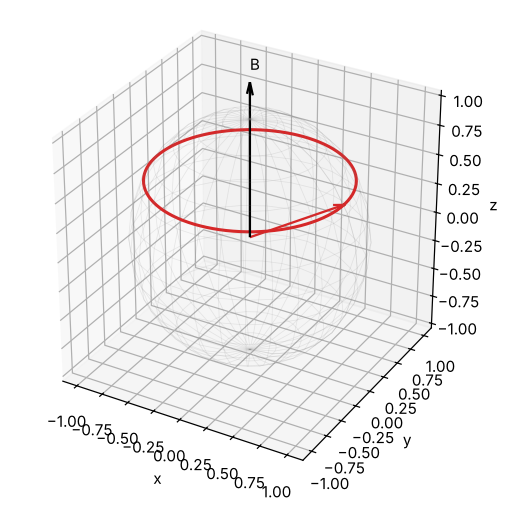

In [3]:
#| label: fig-larmor-precession
#| caption: "Expectation value of the spin of an electron in a field along z, starting at α = 60° from the field. The tip of ⟨S⟩ (in units of ħ/2) traces a circle around the z axis at the Larmor frequency, computed here by evolving the spinor with the 2 × 2 Hamiltonian, not from the formula."
from scipy.linalg import expm
Sx = 0.5 * np.array([[0, 1], [1, 0]]); Sy = 0.5 * np.array([[0, -1j], [1j, 0]]); Sz = 0.5 * np.array([[1, 0], [0, -1]])
alpha = np.pi / 3; chi0 = np.array([np.cos(alpha / 2), np.sin(alpha / 2)], dtype=complex)
Hs = -1.0 * Sz                                  # gamma*B0 = 1, hbar = 1
ts = np.linspace(0, 2 * np.pi, 200)
traj = []
for t in ts:
    chi = expm(-1j * Hs * t) @ chi0
    traj.append([2 * np.real(chi.conj() @ S @ chi) for S in (Sx, Sy, Sz)])
traj = np.array(traj)
fig = plt.figure(figsize=(5.5, 5.5)); ax = fig.add_subplot(projection="3d")
u, v = np.mgrid[0:2 * np.pi:30j, 0:np.pi:15j]
ax.plot_wireframe(np.cos(u) * np.sin(v), np.sin(u) * np.sin(v), np.cos(v), color="gray", alpha=0.15, lw=0.5)
ax.plot(*traj.T, color="tab:red", lw=2)
ax.quiver(0, 0, 0, *traj[0], color="tab:red", arrow_length_ratio=0.1)
ax.quiver(0, 0, 0, 0, 0, 1.3, color="k", arrow_length_ratio=0.08); ax.text(0, 0, 1.4, "B")
ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_zlabel("z"); ax.set_box_aspect((1, 1, 1)); plt.show()

## Adding Angular Momenta

Two spin-½ particles have a four-dimensional spin space, spanned by $|{\uparrow\uparrow}\rangle, |{\uparrow\downarrow}\rangle, |{\downarrow\uparrow}\rangle, |{\downarrow\downarrow}\rangle$. The total spin $\hat{\vec S} = \hat{\vec S}^{(1)} + \hat{\vec S}^{(2)}$ obeys the same algebra, so its states are labeled $|s, m\rangle$. Diagonalizing $\hat S^2$ gives

$$
\underbrace{|1, 1\rangle = |{\uparrow\uparrow}\rangle,\ \ |1, 0\rangle = \tfrac{1}{\sqrt2}\left(|{\uparrow\downarrow}\rangle + |{\downarrow\uparrow}\rangle\right),\ \ |1, -1\rangle = |{\downarrow\downarrow}\rangle}_{\text{triplet},\ s = 1},\qquad
\underbrace{|0, 0\rangle = \tfrac{1}{\sqrt2}\left(|{\uparrow\downarrow}\rangle - |{\downarrow\uparrow}\rangle\right)}_{\text{singlet},\ s = 0} .
$$ (eq-singlet-triplet)

The triplet is symmetric under exchanging the particles and the singlet antisymmetric, which matters enormously for identical particles (topic 7). The code builds the two-particle operators with Kronecker products (operator 1 acts on the first factor, operator 2 on the second) and finds these states.

In [4]:
half = sp.Rational(1, 2)
I2 = sp.eye(2)
S1 = [sp.kronecker_product(half * s, I2) for s in (sx, sy, sz)]
S2 = [sp.kronecker_product(I2, half * s) for s in (sx, sy, sz)]
Stot = [a + b_ for a, b_ in zip(S1, S2)]
S2op = sum((S * S for S in Stot), sp.zeros(4))
for val, mult, vecs in S2op.eigenvects():
    for v in vecs:
        display(Math(r"S^2 = " + sp.latex(val) + r"\hbar^2:\quad " + sp.latex(v.T) + r"\ \text{in basis } (\uparrow\uparrow, \uparrow\downarrow, \downarrow\uparrow, \downarrow\downarrow)"))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In general, combining $j_1$ and $j_2$ gives total $j = |j_1 - j_2|, \ldots, j_1 + j_2$, and

$$
|j, m\rangle = \sum_{m_1 + m_2 = m}C^{j_1j_2j}_{m_1m_2m}\,|j_1m_1\rangle|j_2m_2\rangle ,
$$ (eq-clebsch-gordan)

where the $C$'s are **Clebsch–Gordan coefficients**. You can get them, as above, by diagonalizing $\hat J^2$ in the product basis, or by starting from $|j_1 + j_2, j_1 + j_2\rangle = |j_1j_1\rangle|j_2j_2\rangle$ and applying $\hat J_-$ repeatedly. The next cell checks a few against SymPy's built-in values.

In [5]:
from sympy.physics.quantum.cg import CG
# electron in a p orbital: l = 1 combined with s = 1/2 -> j = 3/2, 1/2
for j, m, m1, m2 in [(sp.Rational(3, 2), half, 1, -half), (sp.Rational(3, 2), half, 0, half),
                     (half, half, 1, -half), (half, half, 0, half)]:
    c = CG(1, m1, half, m2, j, m).doit()
    display(Math(rf"\langle 1,{sp.latex(m1)};\tfrac12,{sp.latex(m2)}\,|\,{sp.latex(j)},{sp.latex(m)}\rangle = " + sp.latex(c)))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

So the $j = \tfrac32$, $m = \tfrac12$ state of a $p$ electron is $\sqrt{1/3}\,|1,1\rangle|{\downarrow}\rangle + \sqrt{2/3}\,|1,0\rangle|{\uparrow}\rangle$, and the $j = \tfrac12$ combination is orthogonal to it. These combinations are the states that fine structure (topic 8) makes stationary.

## Looking Ahead to Level 3

Sakurai builds the rotation operator $e^{-i\hat{\vec J}\cdot\hat n\phi/\hbar}$ and its matrices (the Wigner $D$ functions), and proves the **Wigner–Eckart theorem**: matrix elements of a tensor operator between angular-momentum states factor into a Clebsch–Gordan coefficient (pure geometry) times a reduced matrix element (the physics). Selection rules, such as $\Delta\ell = \pm1$ for electric dipole transitions (topic 10), are the zeros of those Clebsch–Gordan coefficients.

## Exercises

### Exercises

1. An electron is in the state $\chi = A\begin{pmatrix}3i\\4\end{pmatrix}$. Normalize it and find the probabilities of $\pm\hbar/2$ for measurements of $S_z$ and of $S_x$. Find $\langle S_x\rangle$ and $\langle S_z\rangle$.
2. Find the eigenvalues and eigenvectors of $\hat S_y$.
3. Find the Larmor frequency of an electron ($|\gamma| = 1.76\times10^{11}$ s⁻¹T⁻¹) and a proton ($\gamma = 2.68\times10^8$ s⁻¹T⁻¹) in a 1.5 T MRI magnet, in Hz.
4. Show that the singlet state has $\langle\hat{\vec S}^{(1)}\cdot\hat{\vec S}^{(2)}\rangle = -\tfrac34\hbar^2$ and the triplet $+\tfrac14\hbar^2$. (Use $\hat S^2 = \hat S_1^2 + \hat S_2^2 + 2\hat{\vec S}_1\cdot\hat{\vec S}_2$.)
5. An electron with $\ell = 2$: what values can $j$ take? How many states in total, and how many for each $j$?

:::{dropdown} Hints
1. $|A|^2(9 + 16) = 1$. For $S_x$, project onto $|{\rightarrow}\rangle$ and $|{\leftarrow}\rangle$.
2. Characteristic equation of $\tfrac\hbar2\sigma_y$.
3. $f = |\gamma|B/2\pi$.
4. $\hat S_1^2 = \hat S_2^2 = \tfrac34\hbar^2$.
5. $j = \ell\pm\tfrac12$.
:::

:::{dropdown} Answers
1. $A = 1/5$. $S_z$: $P(+) = 9/25$, $P(-) = 16/25$, $\langle S_z\rangle = -\tfrac{7}{50}\hbar$. $S_x$: $P(\pm) = |3i\pm4|^2/50 = \tfrac12$ each, so $\langle S_x\rangle = 0$.
2. $\pm\hbar/2$, with $\tfrac{1}{\sqrt2}(1, \pm i)^T$.
3. Electron: 42 GHz (microwave, used in electron spin resonance). Proton: 64 MHz (radio, the MRI frequency).
4. $\hat{\vec S}_1\cdot\hat{\vec S}_2 = \tfrac12[s(s+1) - \tfrac32]\hbar^2$: $-\tfrac34\hbar^2$ for $s = 0$, $+\tfrac14\hbar^2$ for $s = 1$.
5. $j = \tfrac52$ (6 states) and $\tfrac32$ (4 states): 10 total $= 5\times2$.
:::

## Summary

- Spin is intrinsic angular momentum with the same algebra as $\hat{\vec L}$; electrons have $s = \tfrac12$, described by two-component spinors and $\hat{\vec S} = \tfrac\hbar2\vec\sigma$.
- Measuring along an axis means projecting onto that axis's eigenvectors; $P = \cos^2(\theta/2)$ between axes at angle $\theta$.
- In a field, $\hat H = -\gamma\vec B\cdot\hat{\vec S}$ and $\langle\hat{\vec S}\rangle$ precesses at $\gamma B$.
- Two spin-½: triplet ($s = 1$, symmetric) plus singlet ($s = 0$, antisymmetric). In general $j$ runs from $|j_1 - j_2|$ to $j_1 + j_2$, with Clebsch–Gordan coefficients giving the states.

## Appendix: MyST patterns

Same conventions as the rest of the book: `prf:` directives for definitions, theorems and examples; `:::{dropdown}` for solutions, hints and answers; `$$ ... $$ (label)` with `` {eq}`label` `` for equations; and code cells tagged `hide-input` that start with `#| label:` and `#| caption:` lines.